# 07 — CNN vs Classical Models: Comparison & Error Analysis

Phase 1's best classical model is an **RBF SVM on HOG features** (`rbf_svm_hog`, 91.08% test accuracy), and every
classical model confused Shirt with T-shirt/top, Pullover and Coat. This notebook compares it with the CNNs from
notebook 06 and answers the Phase 2 research questions:

| # | Question |
|---|---|
| RQ5 | Does a small CNN beat the best classical model on accuracy and macro F1? |
| RQ6 | Does the CNN reduce the Shirt / T-shirt / Pullover / Coat confusion? |
| RQ7 | Does a third conv block help? |
| RQ8 | What does the CNN cost (parameters, size, inference time)? |

Everything here reads the **saved** test results (`results/metrics/*_test.json`, including each model's 10,000
predictions). No model is trained or run on the test set again. The image grids also read the true test labels and
images, exactly like Phase 1's notebook 05 (AGENTS.md §4).

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd() if (pathlib.Path.cwd() / "src").exists() else pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src import config, results

FINAL_CNN, OTHER_CNN = "cnn3_images", "cnn2_images"   # final CNN chosen on validation in notebook 06 (D-040)
BEST_CLASSICAL = "rbf_svm_hog"                         # best Phase 1 model by validation (D-029)
COMPARED = [FINAL_CNN, OTHER_CNN, BEST_CLASSICAL, "rbf_svm_pixels"]
saved = {e: json.loads((config.METRICS_DIR / f"{e}_test.json").read_text()) for e in COMPARED}
HOG_MS_PER_1000 = 216  # HOG extraction time per 1,000 images, measured in Phase 1 (D-032)

## 1. The five brief metrics

Accuracy, macro F1 (the average of the 10 per-class F1 scores, so every class counts equally), parameter count /
model-specific size, inference time per 1,000 test images and serialized model size, all from the same `evaluate()`.
The HOG model must also compute HOG features before predicting, so its **end-to-end** time adds 216 ms per 1,000
images. The CNN reads the raw image, so its model time is its end-to-end time.

In [2]:
rows = []
for e in COMPARED:
    t = saved[e]
    extract = HOG_MS_PER_1000 if t["features"] == "hog" else 0
    rows.append({"experiment": e, "test_acc": t["accuracy"], "test_macro_f1": t["macro_f1"],
                 "size measure": f"{t['model_size_detail']['value']:,} {t['model_size_detail']['type'].replace('_', ' ')}",
                 "model_MB": round(t["model_size_bytes"] / 1e6, 2),
                 "inference_ms_per_1000": t["inference_ms_per_1000"],
                 "end_to_end_ms_per_1000": round(t["inference_ms_per_1000"] + extract, 1),
                 "train_time_s": t["train_time_s"]})
metrics_table = pd.DataFrame(rows).set_index("experiment")
display(metrics_table)

errors = {e: int(10000 - round(saved[e]["accuracy"] * 10000)) for e in COMPARED}
print("test errors (of 10,000):", errors)

,test_acc,test_macro_f1,size measure,model_MB,inference_ms_per_1000,end_to_end_ms_per_1000,train_time_s
experiment,,,,,,,
cnn3_images,0.9209,0.9208,"241,546 parameters",0.97,94.43,94.4,416.13
cnn2_images,0.9185,0.9176,"421,642 parameters",1.69,58.36,58.4,198.22
rbf_svm_hog,0.9108,0.9108,"26,343 support vectors",366.21,28876.96,29093.0,451.43
rbf_svm_pixels,0.8970,0.8967,"19,710 support vectors",125.14,4766.94,4766.9,195.67


test errors (of 10,000): {'cnn3_images': 791, 'cnn2_images': 815, 'rbf_svm_hog': 892, 'rbf_svm_pixels': 1030}


Training time: the CNNs trained on 54k images on an Apple M3 CPU (with early stopping); the SVMs' time is their
final fit on 60k on an M3 Pro (Phase 1). They are the same order of magnitude; small differences are not meaningful.

## 2. Per-class recall

Recall for a class = the share of that class's 1,000 test images predicted correctly.

,cnn3_images,cnn2_images,rbf_svm_hog,rbf_svm_pixels,CNN3 − SVM(HOG)
T-shirt/top,88.9,89.4,86.7,85.0,2.2
Trouser,99.3,98.9,97.9,97.2,1.4
Pullover,87.7,87.5,84.9,82.4,2.8
Dress,90.3,93.1,91.1,90.8,-0.8
Coat,87.8,88.0,86.3,83.4,1.5
Sandal,98.4,98.2,97.2,97.0,1.2
Shirt,75.1,69.8,75.2,71.0,-0.1
Sneaker,98.4,97.9,97.0,96.8,1.4
Bag,98.7,98.6,98.4,97.8,0.3
Ankle boot,96.3,97.1,96.1,95.6,0.2


saved results/figures/cnn_recall_vs_classical.png


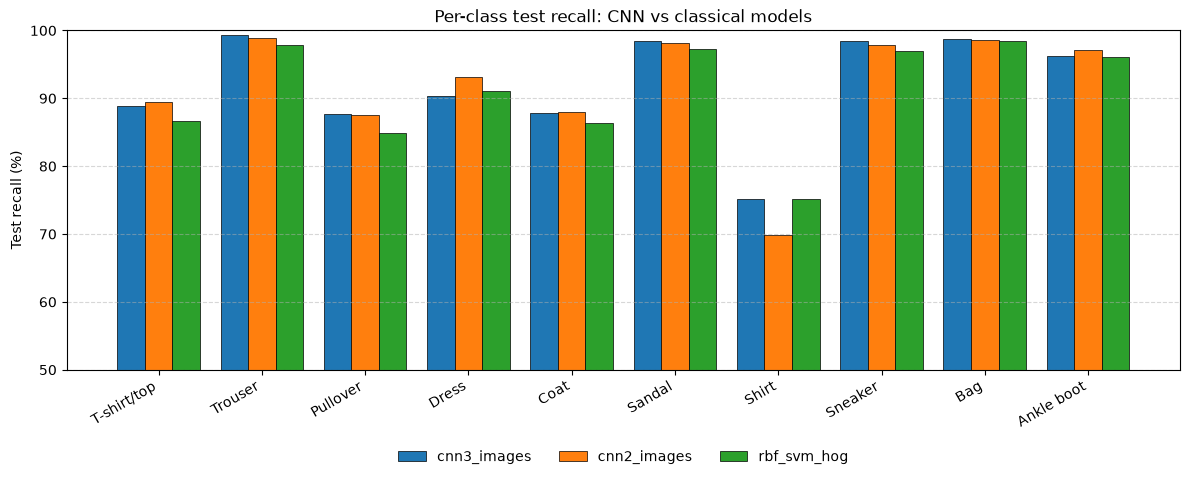

In [3]:
recall = pd.DataFrame({e: np.round(np.array(saved[e]["per_class_recall"]) * 100, 1) for e in COMPARED},
                      index=config.CLASS_NAMES)
recall["CNN3 − SVM(HOG)"] = (recall[FINAL_CNN] - recall[BEST_CLASSICAL]).round(1)
display(recall)
fig = results.plot_recall_comparison([FINAL_CNN, OTHER_CNN, BEST_CLASSICAL])
plt.show()

## 3. Confusion matrices

Rows are the true class, columns the prediction; each row is divided by its total, so the diagonal is the recall.

saved results/figures/errors_confusion_cnn3_images.png


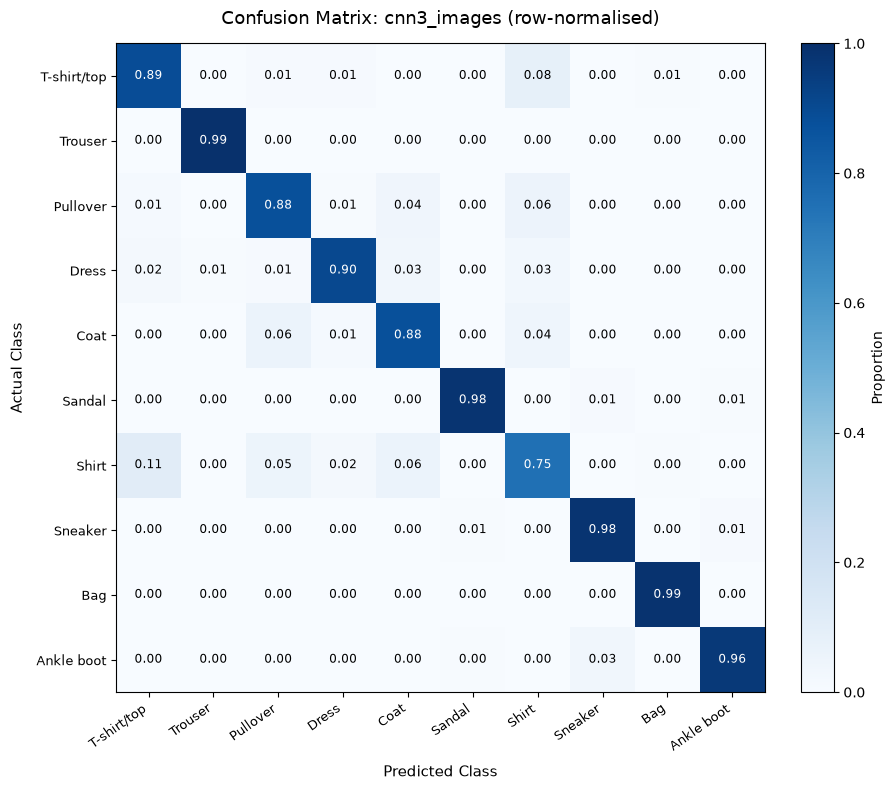

saved results/figures/errors_confusion_cnn2_images.png


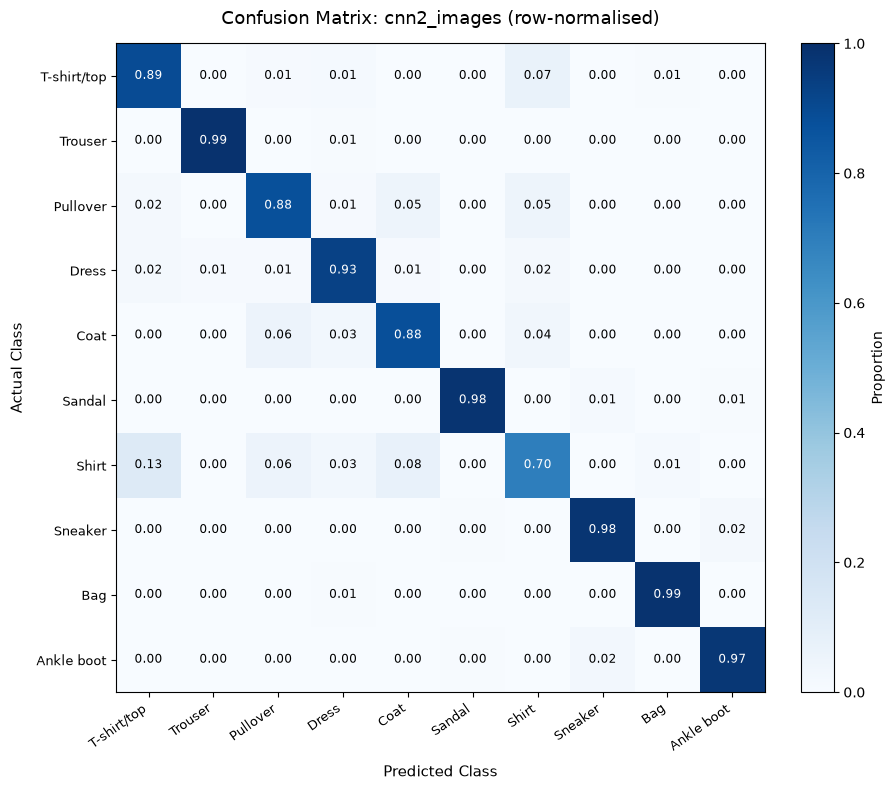

In [4]:
for e in (FINAL_CNN, OTHER_CNN):
    results.plot_confusion(e)
    plt.show()

In [5]:
TOPS = [config.CLASS_NAMES.index(c) for c in ("T-shirt/top", "Pullover", "Coat", "Shirt")]

def errors_among_tops(experiment):
    cm = np.asarray(saved[experiment]["confusion_matrix"])[np.ix_(TOPS, TOPS)]
    return int(cm.sum() - np.trace(cm))

display(pd.DataFrame([{"experiment": e, "all test errors": errors[e],
                       "errors among T-shirt/Pullover/Coat/Shirt": errors_among_tops(e)} for e in COMPARED])
        .set_index("experiment"))

,all test errors,errors among T-shirt/Pullover/Coat/Shirt
experiment,,
cnn3_images,791,539
cnn2_images,815,546
rbf_svm_hog,892,573
rbf_svm_pixels,1030,665


## 4. Most confused pairs: CNN3 vs RBF SVM (HOG)

In [6]:
pairs = {e: results.top_confused_pairs(e, k=6) for e in (FINAL_CNN, BEST_CLASSICAL)}
display(pd.concat(pairs, axis=1))

cnn3_images                            rbf_svm_hog                     \
          true         pred count   rate         true         pred count   
0        Shirt  T-shirt/top   110  0.110        Shirt  T-shirt/top   104   
1  T-shirt/top        Shirt    84  0.084  T-shirt/top        Shirt    91   
2        Shirt         Coat    62  0.062     Pullover        Shirt    66   
3         Coat     Pullover    59  0.059     Pullover         Coat    61   
4     Pullover        Shirt    58  0.058        Shirt         Coat    59   
5        Shirt     Pullover    52  0.052         Coat     Pullover    54   

          
    rate  
0  0.104  
1  0.091  
2  0.066  
3  0.061  
4  0.059  
5  0.054

## 5. AML vs CNN confusion examples

For the three pairs both models confuse most, the grids show the **first** test images (in test-set order, not
hand-picked) of the true class that each model labels as the wrong class. Same pair, two models: the classical model
(handcrafted HOG features) above, the CNN (learned features) below.

saved results/figures/errors_misclassified_rbf_svm_hog_shirt_vs_t-shirt_top.png


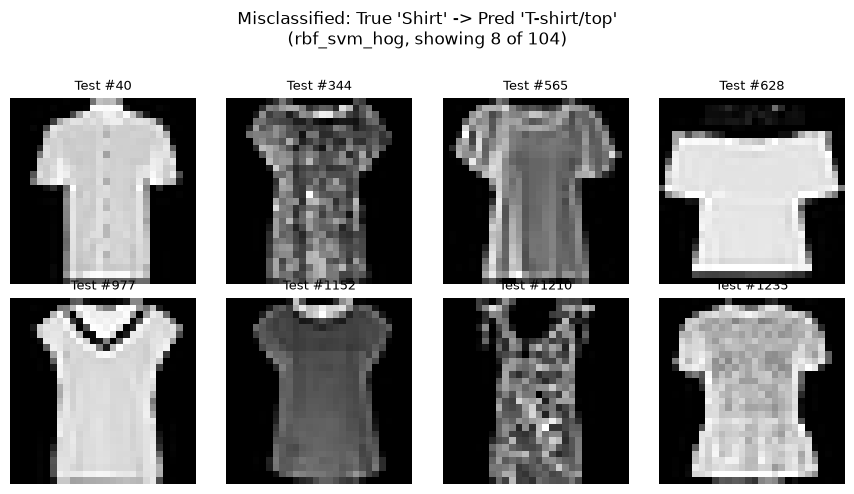

saved results/figures/errors_misclassified_cnn3_images_shirt_vs_t-shirt_top.png


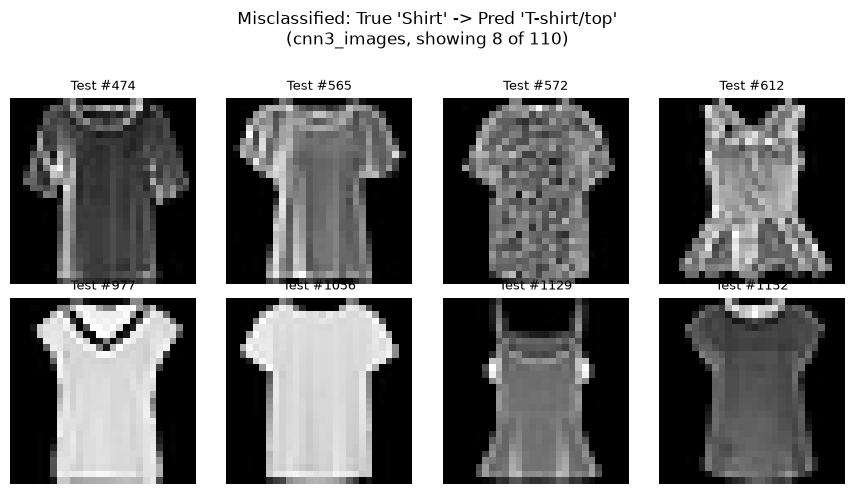

saved results/figures/errors_misclassified_rbf_svm_hog_t-shirt_top_vs_shirt.png


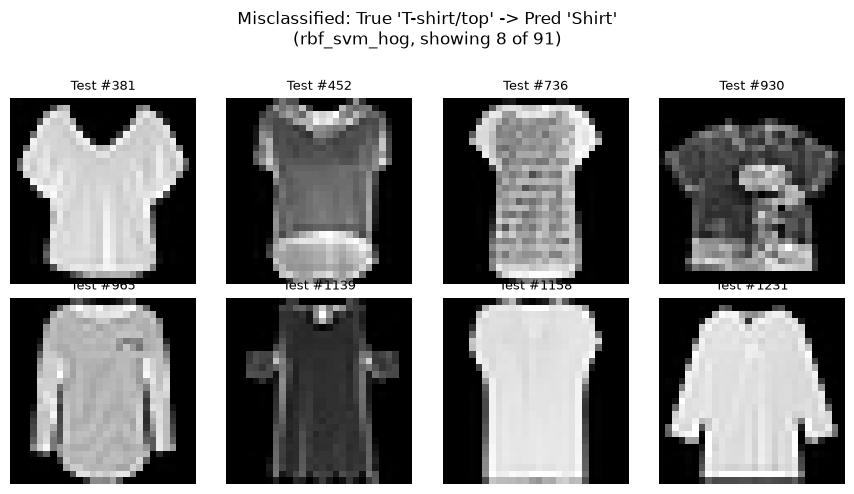

saved results/figures/errors_misclassified_cnn3_images_t-shirt_top_vs_shirt.png


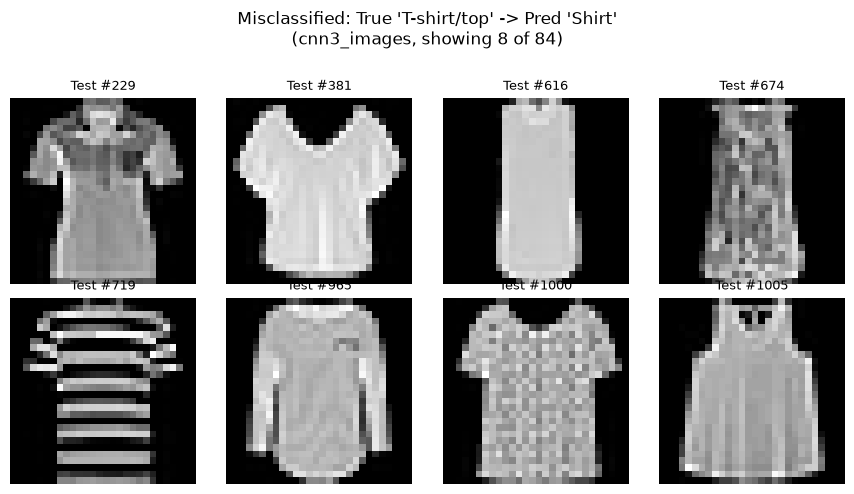

saved results/figures/errors_misclassified_rbf_svm_hog_shirt_vs_coat.png


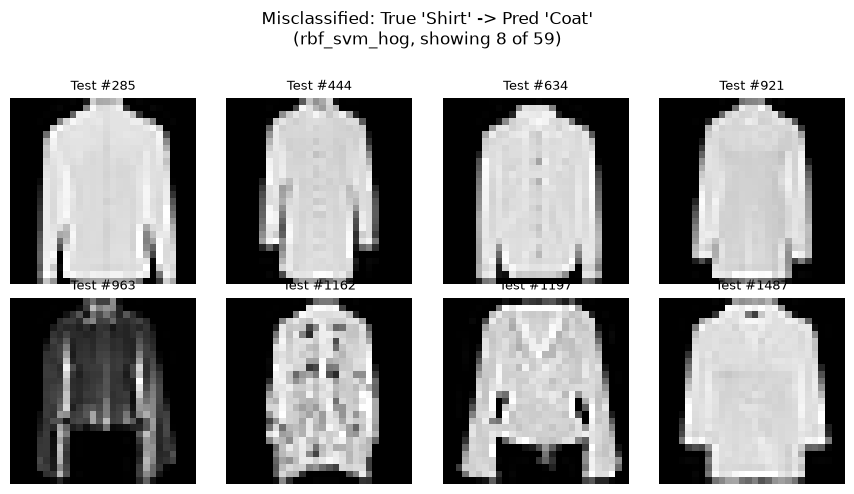

saved results/figures/errors_misclassified_cnn3_images_shirt_vs_coat.png


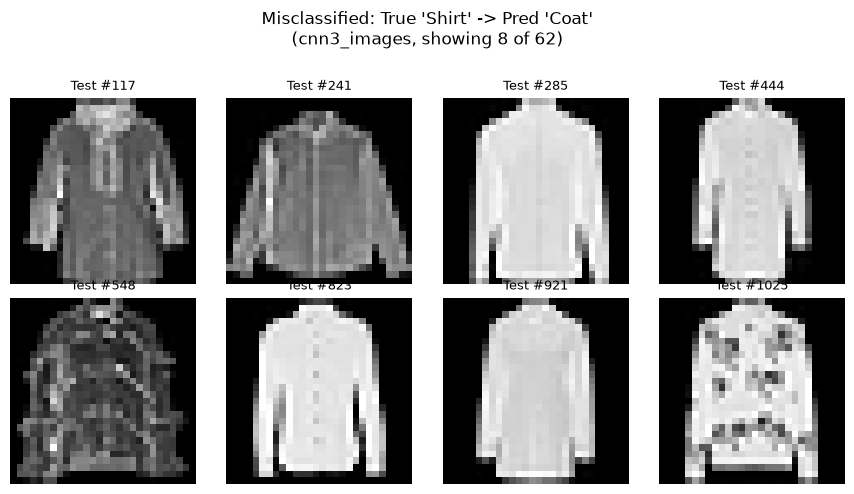

In [7]:
EXAMPLE_PAIRS = [("Shirt", "T-shirt/top"), ("T-shirt/top", "Shirt"), ("Shirt", "Coat")]
for true_c, pred_c in EXAMPLE_PAIRS:
    for e in (BEST_CLASSICAL, FINAL_CNN):
        results.plot_misclassified(e, true_c, pred_c, n=8, tag=e)
        plt.show()

## 6. Do the two models make the same mistakes?

`model_agreement` compares the saved predictions image by image. Images that **both** models get wrong, especially
with the **same** wrong label, are likely ambiguous at 28×28 rather than a weakness of one model.

In [8]:
agreement = {f"{FINAL_CNN} vs {BEST_CLASSICAL}": results.model_agreement(FINAL_CNN, BEST_CLASSICAL),
             f"{FINAL_CNN} vs {OTHER_CNN}": results.model_agreement(FINAL_CNN, OTHER_CNN)}
display(pd.DataFrame(agreement))

y_test = results.load_splits(verbose=False)["y_test"]
cnn, svm = np.asarray(saved[FINAL_CNN]["y_pred"]), np.asarray(saved[BEST_CLASSICAL]["y_pred"])
shirt = y_test == config.CLASS_NAMES.index("Shirt")
s = config.CLASS_NAMES.index("Shirt")
print("Shirt test images (1,000):",
      {"both right": int(np.sum(shirt & (cnn == s) & (svm == s))),
       "only CNN3 right": int(np.sum(shirt & (cnn == s) & (svm != s))),
       "only SVM right": int(np.sum(shirt & (cnn != s) & (svm == s))),
       "both wrong": int(np.sum(shirt & (cnn != s) & (svm != s)))})

,cnn3_images vs rbf_svm_hog,cnn3_images vs cnn2_images
both_correct,8792.0,8944.00
both_incorrect,475.0,550.00
only_a_incorrect,316.0,241.00
only_b_incorrect,417.0,265.00
same_wrong_label,398.0,493.00
total,10000.0,10000.00
agreement_pct,91.9,94.37


Shirt test images (1,000): {'both right': 661, 'only CNN3 right': 90, 'only SVM right': 91, 'both wrong': 158}


## 7. Error analysis and answers

**RQ5 — Does the CNN beat the best classical model? Yes, by about one point.** CNN3 reaches **92.09%** test accuracy
and **0.9208** macro F1, against 91.08% and 0.9108 for the RBF SVM on HOG: 791 errors instead of 892, i.e. 101 fewer
mistakes out of 10,000. CNN2 (91.85%, 0.9176) also beats it. The gain is modest: HOG already captured most of what
separates these classes.

**RQ6 — Does the CNN fix the Shirt confusion? No.** Shirt recall is 75.1% for CNN3 and 75.2% for the SVM, and the
single biggest confusion is still Shirt → T-shirt/top (110 vs 104 images). Image by image the two models are not even
fixing the same shirts: CNN3 gets 90 shirts right that the SVM misses, the SVM gets 91 right that CNN3 misses, and
**158 shirts are wrong for both**. What the CNN does improve is the other tops: T-shirt/top +2.2, Pullover +2.8 and
Coat +1.5 points of recall, so errors among the four tops fall from 573 to 539. It is also more careful about
*predicting* Shirt: fewer non-shirts are labelled Shirt (Shirt precision 77.4% vs 75.3%).

**Why Shirt stays hard.** At 28×28 pixels a shirt, a T-shirt, a pullover and a coat share the same torso silhouette;
what separates them (a collar, a button placket, a cuff, fabric texture) is a handful of pixels, and some images are
genuinely ambiguous. The Shirt → T-shirt/top grids in §5 show this directly: most of the "shirts" both models miss are
short-sleeved, collarless tops that look like T-shirts, and some are sleeveless tank tops (test #612, #1129). For
images like these the label itself is debatable, so no model trained on these labels can be expected to get them right. The grids also show the swap
image by image: CNN3 correctly calls test #40 a Shirt, where its **button placket** is visible, and also #344 and #628,
all of which the SVM calls T-shirt/top; the SVM in turn gets #474, #572, #612, #1056 and #1129 right, which CNN3 calls
T-shirt/top. Learned filters pick up some details HOG misses, and miss some that HOG's gradients catch.
Learned filters help where the cue is a shape the network can find (sleeve length, a hem, the outline of a coat), but
cannot recover detail the low resolution has removed. The agreement numbers support this: **475 test images are wrong
for both models, and 398 of them get the same wrong label** from both, a sign the images themselves are ambiguous.

**RQ7 — Does a third block help? Not clearly.** CNN3 beats CNN2 by 0.24 points on test (92.09% vs 91.85%), the same
direction as on validation, but notebook 06 showed that run-to-run variation is about as large (D-040). The two
networks trade classes: CNN3 is much better on Shirt (75.1% vs 69.8%), CNN2 on Dress (93.1% vs 90.3%). What the third
block clearly buys is size: CNN3 has 43% fewer parameters, because the extra pooling shrinks the dense layer.

**RQ8 — What does the CNN cost? Much less than the SVM.** CNN3 predicts 1,000 images in about **94 ms** on 4 CPU
threads, about 300 times faster than the RBF SVM's ~29 s (28.9 s model time + 0.2 s HOG extraction), and it is
**0.97 MB** (241,546 parameters) against **366 MB** for the SVM, which must store its 26,343 support vectors. Training
took a similar few minutes on a laptop CPU. So the CNN is better, smaller and faster at once; the classical models'
only advantage is that they need no deep-learning library.

**Summary.** A small CNN that learns its own filters beats the best handcrafted-feature model by about one point and is
two orders of magnitude cheaper to run, but it does not solve the Shirt problem: the remaining errors are concentrated
in the same ambiguous tops, and most of them are shared with the classical model.